# 05 — Исследование на году 1

**Цель:** улучшить стратегию v1, глядя **только на год 1** (окт 2024 – сен 2025).
Год 2 не трогаем до самой последней проверки. Иначе мы бы подгоняли стратегию под данные, на которых потом её оцениваем.

**Правила исследования:**
- меняем **одну вещь за раз**, тогда понятно, что именно помогло;
- каждый запуск пишем в журнал `log`, а в отчёте честно показываем, сколько вариантов попробовали;
- смотрим два уровня комиссий: **VIP-7** (дешёвый) и **Regular** (дорогой). VIP-4 всегда между ними;
- выбираем **плато** (несколько соседних значений работают похоже хорошо), а не одну случайно лучшую точку.

## 1. Setup

Ноутбук лежит в папке `notebooks/`, а наш код — в корне проекта (`config.py`, `src/`).
Поэтому добавляем корень проекта в `sys.path`, иначе `import config` не найдётся.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent                 # notebooks/ → на папку выше = корень проекта
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))        # теперь Python видит config.py и src/

from datetime import datetime, timezone
import numpy as np
import polars as pl

import config
from src.funding import load_funding, funding_on_bars
from src.research import evaluate        # один прогон стратегии → метрики

## 2. Данные и фандинг

- `df` — 5-минутные свечи пары. Колонки с `_a` относятся к ETH, с `_b` к BTC.
- `fa`, `fb` — ставка фандинга **на каждой свече**. В свечи 00:00, 08:00 и 16:00 UTC это настоящая ставка, во всех остальных 0.

In [2]:
df = pl.read_parquet(config.PROCESSED_DIR / "pair_5m.parquet")

open_time = df["open_time"].to_numpy()
fa = funding_on_bars(open_time, load_funding(config.SYMBOL_A))     # фандинг ETH на каждой свече
fb = funding_on_bars(open_time, load_funding(config.SYMBOL_B))     # фандинг BTC на каждой свече

print("свечей:", df.shape[0], "| фандинг:", fa.shape, fb.shape)   # все три длины должны совпасть

свечей: 210240 | фандинг: (210240,) (210240,)


## 3. Граница года 1

`split` — номер первой свечи года 2 (2025-10-01 00:00 UTC).

- Год 1 = свечи с `0` до `split` (не включая).
- В году 365 дней × 288 свечей в день, поэтому ожидаем `split = 105 120`.

In [3]:
oos = datetime.fromisoformat(config.OOS_START).replace(tzinfo=timezone.utc)   # "2025-10-01" → дата в UTC
oos_ms = int(oos.timestamp() * 1000)                                         # → миллисекунды, как open_time

split = int((df["open_time"] < oos_ms).sum())    # сколько свечей раньше начала года 2
print("split =", split)
assert split == 105_120                          # если не так — с данными что-то не то

split = 105120


## 4. Журнал экспериментов

`record(name, **params)` делает три вещи:
1. прогоняет стратегию на году 1 **два раза**, для VIP-7 и для Regular;
2. дописывает обе строки в журнал `log`;
3. возвращает весь журнал как таблицу.

`params` — то, что меняем в этом эксперименте, например `max_loss=200.0`.
Всё, что не передали, берётся из `config` (окно 288, вход 2, стоп 4, время 576).

Пример: `record("loss $200", max_loss=200.0)` → в журнале появятся 2 строки: vip7 и regular.

In [ ]:
log = []                                  # сюда копятся ВСЕ запуски
TIERS = ("vip7", "regular")               # дешёвые и дорогие комиссии

# какие колонки показывать (порядок = порядок в таблице)
COLS = ["name", "tier",
        "window", "entry_z", "stop_z", "max_hold",                         # параметры сигнала и выхода
        "max_loss", "max_loss_pct", "beta_window", "exit_z",               # дополнительные правила (0 = выкл)
        "n_trades", "win_rate", "avg_trade", "profit_factor",              # сделки
        "total_return", "max_drawdown", "sharpe", "min_equity", "exposure"]  # капитал


def record(name, **params):
    for tier in TIERS:
        row = evaluate(df, fa, fb, split, tier=tier, **params)   # один прогон → словарь метрик
        row["name"] = name                                       # подпись эксперимента
        log.append(row)
    table = pl.DataFrame(log)
    return table.select([c for c in COLS if c in table.columns])   # показываем только существующие колонки

## 5. Baseline — v1 на году 1

Оба новых стопа по умолчанию выключены (`0`), поэтому результат **должен совпасть** со старым.
Это проверка, что новый код ничего не сломал.

| VIP-7         | ожидаем |
|---------------|---------|
| сделок        | 483     |
| return        | −34.7%  |
| max drawdown  | −37.2%  |
| profit factor | 0.768   |
| Sharpe        | −1.76   |

In [5]:
table = record("baseline")
table

name,tier,window,entry_z,stop_z,max_hold,max_loss,max_loss_pct,beta_window,n_trades,win_rate,avg_trade,profit_factor,total_return,max_drawdown,sharpe,min_equity,exposure
str,str,i64,f64,f64,i64,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""baseline""","""vip7""",288,2.0,4.0,576,0.0,0.0,0,483,0.616977,-14.350058,0.767516,-0.346554,-0.372496,-1.758088,12722.659463,0.558381
"""baseline""","""regular""",288,2.0,4.0,576,0.0,0.0,0,483,0.581781,-25.559567,0.613962,-0.617264,-0.631405,-3.172942,7386.373153,0.558381


## 6. Эксперимент 4.1 — стоп по убытку сделки

**Проблема v1.** Когда спред трендит, скользящее среднее едет вслед за ним, и z остаётся около 2–3.
z-стоп (|z| > 4) не срабатывает, сделка висит до time-стопа (2 дня) и теряет до **−$1,920**.

**Новое правило.** Если открытая сделка в минусе больше порога, выходим на open следующей свечи
(причина `loss`), потом пауза, пока |z| не станет меньше 2.

**Как сработает на примере** (шорт спреда, порог $200):
- вход: ETH = 2,500 (шорт 4 ETH), BTC = 62,500 (лонг 0.16 BTC), комиссия −$6.40;
- ETH вырос до 2,550, BTC стоит: −4 × 50 − 6.40 = **−206.40** < −200 → выходим.
- Проще говоря, $200 ≈ ETH обогнал BTC на ~2%.

**Два способа задать порог:**

| | Вариант 1: % от ноги | Вариант 2: % от капитала при входе |
|---|---|---|
| Формула | % × $10,000 | % × капитал перед входом |
| Капитал $20,000, 1% / 2% | $200 | $200 |
| Капитал $13,000 | $200 (не меняется) | $130 (строже) |

Сетки подобраны так, что при капитале $20,000 оба варианта дают одинаковые $100 … $500.
Разница появляется только когда капитал падает.

In [6]:
# Вариант 1: % от ноги ($10,000) → $100, $150, $200, $300, $500
for pct in (0.01, 0.015, 0.02, 0.03, 0.05):
    table = record(f"loss {pct:.1%} of leg", max_loss=pct * config.NOTIONAL)

# Вариант 2: % от капитала при входе (при $20,000 → те же $100 … $500)
for pct in (0.005, 0.0075, 0.01, 0.015, 0.025):
    table = record(f"loss {pct:.2%} of equity", max_loss_pct=pct)

table

name,tier,window,entry_z,stop_z,max_hold,max_loss,max_loss_pct,beta_window,n_trades,win_rate,avg_trade,profit_factor,total_return,max_drawdown,sharpe,min_equity,exposure
str,str,i64,f64,f64,i64,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""baseline""","""vip7""",288,2.0,4.0,576,0.0,0.0,0,483,0.616977,-14.350058,0.767516,-0.346554,-0.372496,-1.758088,12722.659463,0.558381
"""baseline""","""regular""",288,2.0,4.0,576,0.0,0.0,0,483,0.581781,-25.559567,0.613962,-0.617264,-0.631405,-3.172942,7386.373153,0.558381
"""loss 1.0% of leg""","""vip7""",288,2.0,4.0,576,100.0,0.0,0,641,0.513261,-10.65475,0.811099,-0.341485,-0.358297,-2.00857,12862.839437,0.445234
"""loss 1.0% of leg""","""regular""",288,2.0,4.0,576,100.0,0.0,0,651,0.480799,-23.878692,0.616333,-0.777251,-0.788833,-4.24403,4231.634849,0.441486
"""loss 1.5% of leg""","""vip7""",288,2.0,4.0,576,150.0,0.0,0,579,0.571675,-13.050018,0.78678,-0.377798,-0.391538,-2.185896,12203.52822,0.484551
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""loss 1.00% of equity""","""regular""",288,2.0,4.0,576,0.0,0.01,0,613,0.512235,-22.566038,0.643651,-0.691649,-0.698958,-4.068651,6032.662213,0.462224
"""loss 1.50% of equity""","""vip7""",288,2.0,4.0,576,0.0,0.015,0,536,0.608209,-15.310086,0.762869,-0.41031,-0.434928,-2.173274,11435.822053,0.516134
"""loss 1.50% of equity""","""regular""",288,2.0,4.0,576,0.0,0.015,0,563,0.557726,-24.423556,0.62934,-0.687523,-0.699843,-3.778743,6014.925721,0.495786


In [7]:
with pl.Config(tbl_rows=-1):
    print(table.filter(pl.col("tier") == "vip7")
               .select("name", "n_trades", "win_rate", "avg_trade",
                       "profit_factor", "total_return", "max_drawdown", "sharpe"))

shape: (11, 8)
┌────────────┬──────────┬──────────┬────────────┬────────────┬────────────┬────────────┬───────────┐
│ name       ┆ n_trades ┆ win_rate ┆ avg_trade  ┆ profit_fac ┆ total_retu ┆ max_drawdo ┆ sharpe    │
│ ---        ┆ ---      ┆ ---      ┆ ---        ┆ tor        ┆ rn         ┆ wn         ┆ ---       │
│ str        ┆ i64      ┆ f64      ┆ f64        ┆ ---        ┆ ---        ┆ ---        ┆ f64       │
│            ┆          ┆          ┆            ┆ f64        ┆ f64        ┆ f64        ┆           │
╞════════════╪══════════╪══════════╪════════════╪════════════╪════════════╪════════════╪═══════════╡
│ baseline   ┆ 483      ┆ 0.616977 ┆ -14.350058 ┆ 0.767516   ┆ -0.346554  ┆ -0.372496  ┆ -1.758088 │
│ loss 1.0%  ┆ 641      ┆ 0.513261 ┆ -10.65475  ┆ 0.811099   ┆ -0.341485  ┆ -0.358297  ┆ -2.00857  │
│ of leg     ┆          ┆          ┆            ┆            ┆            ┆            ┆           │
│ loss 1.5%  ┆ 579      ┆ 0.571675 ┆ -13.050018 ┆ 0.78678    ┆ -0.377798  ┆ 

## 9. Вывод по эксперименту 4.1 — стоп по убытку сделки

### Что проверяли

**Проблема v1.** Когда спред трендит, скользящее среднее едет вслед за ним, и z остаётся около 2–3.
z-стоп (|z| > 4) не срабатывает, и сделка держится до time-стопа. Отсюда самые большие убытки (до −$1,920).

**Идея.** Выходить, если открытая сделка в минусе больше порога. Выход на open следующей свечи,
причина `loss`, потом пауза до |z| < 2.

**Варианты (10 штук, только год 1):**
- **% от ноги ($10,000):** 1%, 1.5%, 2%, 3%, 5% → порог $100 … $500;
- **% от капитала при входе:** 0.5%, 0.75%, 1%, 1.5%, 2.5% → при $20,000 те же $100 … $500, при падении капитала строже.

### Результаты (VIP-7)

| Вариант          | Сделок | Win rate | Avg trade | PF    | Return     | Max DD     | Sharpe    |
|------------------|--------|----------|-----------|-------|------------|------------|-----------|
| **baseline**     | 483    | 61.7%    | −14.35    | 0.768 | **−34.7%** | **−37.2%** | **−1.76** |
| 1% ноги          | 641    | 51.3%    | −10.65    | 0.811 | −34.1%     | −35.8%     | −2.01     |
| 1.5% ноги        | 579    | 57.2%    | −13.05    | 0.787 | −37.8%     | −39.2%     | −2.19     |
| 2% ноги          | 546    | 59.9%    | −14.55    | 0.771 | −39.7%     | −42.4%     | −2.18     |
| 3% ноги          | 516    | 60.9%    | −17.87    | 0.731 | −46.1%     | −48.5%     | −2.42     |
| 5% ноги          | 496    | 61.5%    | −15.38    | 0.758 | −38.1%     | −40.7%     | −1.96     |
| 0.5% капитала    | 714    | 43.1%    | −13.64    | 0.746 | −48.7%     | −49.8%     | −3.03     |
| 0.75% капитала   | 616    | 53.4%    | −12.34    | 0.792 | −38.0%     | −39.7%     | −2.10     |
| 1% капитала      | 574    | 58.2%    | −13.42    | 0.782 | −38.5%     | −40.8%     | −2.23     |
| 1.5% капитала    | 536    | 60.8%    | −15.31    | 0.763 | −41.0%     | −43.5%     | −2.17     |
| 2.5% капитала    | 498    | 61.4%    | −14.72    | 0.765 | −36.7%     | −39.3%     | −1.92     |

На **Regular** проверенные варианты тоже хуже baseline: −69% … −78% против −61.7%.

### Что видно

1. **Sharpe хуже baseline во всех 10 вариантах.** Ни один порог не улучшил стратегию.
2. **Плато нет.** Результаты скачут без системы: 3% ноги хуже, чем 2% и 5%. Это шум, а не закономерность.
3. **Единственный «почти равный» вариант (1% ноги, −34.1%)** не стабилен: Sharpe хуже, а на Regular он падает до −77.7%.
4. **Даже мягкий стоп ($500) вредит.** Сделок всего на 13 больше, а return хуже на 3.5 п.п. (≈ $700).
5. **% от капитала не лучше, чем % от ноги.**

### Почему стоп не помогает

- **Он режет сделки, которые потом вернулись бы к среднему.**
  Многие сделки временно уходят в −$100…−$500, а затем закрываются по `mean` в плюс.
  Стоп превращает временный минус в настоящий убыток, поэтому win rate падает (61.7% → 43–61%).
- **Больше сделок — больше комиссий.**
  Пример: 1% ноги даёт 641 сделку вместо 483, то есть +158 × $12.80 ≈ **−$2,000** только на комиссиях (VIP-7).
  На Regular каждая сделка стоит $24, поэтому там ещё хуже.
- **Катастрофических сделок мало**, а стоп задевает сотни обычных.

### Решение

> **Стоп по убытку отклонён.** В v2 он выключен (`max_loss = 0`, `max_loss_pct = 0`).
> Код оставлен в движке и покрыт тестами, его можно включить в любой момент.

**Главный урок:** проблему тренда нельзя решить **на выходе**, потому что это режет и хорошие сделки.
Её надо решать **на входе**: не открывать сделку, пока спред трендит.
→ Следующий эксперимент: **4.4 — режимный фильтр**.

**Сколько вариантов попробовано:** 10 (+ baseline). Все записаны в `reports/research_log_year1.csv`.

## 10. Эксперимент 4.4 — режимный фильтр. Диагностика

**Вопрос:** можно ли **в момент входа** понять, что сделка будет плохой?
Если да, такую сделку просто не открываем (фильтр на входе).

**Что делаем:** движок не меняем. Берём 483 сделки baseline года 1 и для каждой смотрим,
какие признаки были **в момент решения о входе** (свеча `entry_t − 1`).

### 10.1 Признак 1: недельный z (`z_long`)

- Дневной z (окно 288 = 1 день) — по нему мы входим.
- Недельный z (окно 2016 = 7 дней). Его среднее двигается медленно, поэтому тренд в нём виден.

**Гипотеза:** если |z_long| большой, спред трендит всю неделю, и сделка будет плохой.

**Пример:**
- z_day = 2.5, z_long = 0.8 → короткий всплеск → должна быть хорошей;
- z_day = 2.5, z_long = 3.2 → неделя тренда → должна быть плохой.

**Важно:** первые 2015 свечей `z_long = NaN` (не хватает недели истории), это как 287 NaN у дневного z.

In [8]:
from src.signals import log_spread, rolling_zscore
from src.engine_numba import run_backtest_fast

LONG_WINDOW = 2016                                     # 7 дней × 288 свечей

open_a, open_b = df["open_a"].to_numpy(), df["open_b"].to_numpy()
close_a, close_b = df["close_a"].to_numpy(), df["close_b"].to_numpy()
tradable = ((df["n_traded_a"] > 0) & (df["n_traded_b"] > 0)).to_numpy()

spread = log_spread(close_a, close_b)
z = rolling_zscore(spread, config.WINDOW)              # дневной z (как в v1)
z_long = rolling_zscore(spread, LONG_WINDOW)           # недельный z

cut = slice(0, split)                                  # только год 1
res = run_backtest_fast(open_a[cut], open_b[cut], close_a[cut], close_b[cut],
                        tradable[cut], z[cut], "vip7", fa[cut], fb[cut])

tr = pl.DataFrame(res["trades"])
decision = tr["entry_t"].to_numpy() - 1                # решение принято на свече до входа
tr = tr.with_columns(pl.Series("z_long", z_long[cut][decision]))
tr.head()

entry_t,exit_t,direction,reason,pnl,funding,z_long
i64,i64,i64,str,f64,f64,f64
449,881,1,"""mean""",-286.610092,0.254947,NaN
1056,1060,-1,"""stop""",-71.824791,0.0,NaN
1074,1187,-1,"""mean""",40.371795,1.15612,NaN
1378,1411,1,"""mean""",23.841188,0.0,NaN
1469,1634,-1,"""mean""",0.279337,0.106348,NaN


### Группы по |z_long|

Сделки без `z_long` (первая неделя данных, 9 сделок) убираем: иначе `cut` может отправить NaN в последнюю группу.

Колонки:
- `n` — сколько сделок в группе;
- `avg_pnl` — средний PnL сделки (после комиссий VIP-7);
- `total_pnl` — сумма PnL группы;
- `bad_exit` — доля выходов **не** по `mean` (stop, time, end).

In [9]:
# сделки без z_long (первая неделя данных) не учитываем
tr_ok = tr.filter(pl.col("z_long").is_not_nan())
print("всего сделок:", tr.height, "| с z_long:", tr_ok.height)

# группы по |z_long| в момент входа
summary_long = (
    tr_ok.with_columns(pl.col("z_long").abs().cut([1.0, 1.5, 2.0, 2.5, 3.0]).alias("abs_z_long"))
         .group_by("abs_z_long")
         .agg(
             n=pl.len(),                                          # сколько сделок
             avg_pnl=pl.col("pnl").mean(),                        # средний PnL
             total_pnl=pl.col("pnl").sum(),                       # сумма PnL
             bad_exit=(pl.col("reason") != "mean").mean(),        # доля выходов не по mean
         )
         .sort("abs_z_long")
)
summary_long

всего сделок: 483 | с z_long: 474


/var/folders/3v/_ckk_f1s2fd38003ltvg908h0000gn/T/ipykernel_9512/3116679573.py:7: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  tr_ok.with_columns(pl.col("z_long").abs().cut([1.0, 1.5, 2.0, 2.5, 3.0]).alias("abs_z_long"))


abs_z_long,n,avg_pnl,total_pnl,bad_exit
enum,u32,f64,f64,f64
"""(-inf, 1]""",236,-25.639885,-6051.012832,0.228814
"""(1, 1.5]""",111,-17.916376,-1988.717712,0.234234
"""(1.5, 2]""",64,13.256603,848.422575,0.109375
"""(2, 2.5]""",33,-18.49611,-610.37162,0.212121
"""(2.5, 3]""",17,3.618836,61.520216,0.117647
"""(3, inf]""",13,79.017376,1027.225885,0.076923


**Результат — обратный гипотезе:**

| \|z_long\|  | Сделок | Avg PnL | Сумма  |
|-----------|--------|---------|--------|
| ≤ 1       | 236    | −25.6   | −6,051 |
| 1 – 1.5   | 111    | −17.9   | −1,989 |
| 1.5 – 2   | 64     | +13.3   | +848   |
| 2 – 2.5   | 33     | −18.5   | −610   |
| 2.5 – 3   | 17     | +3.6    | +62    |
| > 3       | 13     | +79.0   | +1,027 |

- Худшие сделки — при **маленьком** |z_long|, а не при большом.
- Но в верхних группах мало сделок (13, 17), и картина не монотонная (2–2.5 снова в минусе).

**Новая гипотеза:** может, дело в размере отклонения **в деньгах**: маленькое отклонение даёт маленькую прибыль, и её съедают комиссии. Проверяем ниже.

### 10.2 Признак 2: отклонение спреда от среднего в bp (`dist_bp`)

`dist_bp = |спред − дневное среднее| × 10 000`

Если спред вернётся к среднему, прибыль ≈ dist_bp долларов: 1 bp движения спреда ≈ $1 на ноге $10,000.
Комиссии: VIP-7 = 12.8 bp на сделку, Regular = 24 bp.

**Гипотеза:** чем больше отклонение, тем больше прибыль от возврата → тем лучше сделка.

`qcut(5)` делит сделки на 5 групп **с одинаковым числом сделок** (~95), чтобы ни одна группа не держалась на 13 сделках.

In [10]:
# отклонение спреда от дневного среднего в bp (1 bp ≈ $1 на ноге $10 000)
s = pl.Series(spread)
dist_bp = ((s - s.rolling_mean(config.WINDOW)).abs() * 10_000).to_numpy()

tr_ok = tr_ok.with_columns(pl.Series("dist_bp", dist_bp[cut][tr_ok["entry_t"].to_numpy() - 1]))

summary_dist = (
    tr_ok.with_columns(pl.col("dist_bp").qcut(5).alias("dist_group"))   # 5 групп по ~95 сделок
         .group_by("dist_group")
         .agg(
             n=pl.len(),
             avg_dist_bp=pl.col("dist_bp").mean(),                 # среднее отклонение в группе
             avg_pnl=pl.col("pnl").mean(),
             total_pnl=pl.col("pnl").sum(),
             bad_exit=(pl.col("reason") != "mean").mean(),
         )
         .sort("avg_dist_bp")
)
summary_dist

/var/folders/3v/_ckk_f1s2fd38003ltvg908h0000gn/T/ipykernel_9512/2659897438.py:8: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  tr_ok.with_columns(pl.col("dist_bp").qcut(5).alias("dist_group"))   # 5 групп по ~95 сделок


dist_group,n,avg_dist_bp,avg_pnl,total_pnl,bad_exit
cat,u32,f64,f64,f64,f64
"""(-inf, 63.33867008689431]""",95,48.339486,-14.299005,-1358.405505,0.231579
"""(63.33867008689431, 86.3147887…",95,74.917663,0.90856,86.313203,0.221053
"""(86.31478872854004, 120.434140…",94,102.699381,-52.735884,-4957.173065,0.255319
"""(120.43414038802425, 180.96793…",95,146.555086,-14.725192,-1398.893202,0.221053
"""(180.96793866376265, inf]""",95,278.255188,9.633948,915.225081,0.094737


**Результат — связи нет:**

| Отклонение | Avg PnL | Сумма  |
|------------|---------|--------|
| 48 bp      | −14.3   | −1,358 |
| 75 bp      | +0.9    | +86    |
| 103 bp     | −52.7   | −4,957 |
| 147 bp     | −14.7   | −1,399 |
| 278 bp     | +9.6    | +915   |

- PnL прыгает и не растёт с отклонением.
- Даже минимальное отклонение (48 bp) в 4 раза больше комиссий VIP-7. **Дело не в комиссиях.**
- Группу 103 bp тянут вниз несколько огромных сделок. Одна сделка на −1,920 сдвигает среднее группы на −20.
  → **среднее — шумная метрика.** Нужны медиана и win rate.

### 10.3 Устойчивая проверка + 10 худших сделок

1. **Медиана PnL** — «типичная» сделка. Одна сделка на −1,920 на неё не влияет.
2. **Win rate** — доля прибыльных сделок.
3. **10 худших сделок** — какие у них были `z_long` и `dist_bp` в момент входа?
   Если они раскиданы по всем группам, фильтр на входе их не поймает.

In [11]:
# 1) устойчивые метрики по группам: медиана и win rate не ломаются от 1–2 огромных сделок
robust = (
    tr_ok.with_columns(
        pl.col("z_long").abs().qcut(5).alias("z_long_group"),
        pl.col("dist_bp").qcut(5).alias("dist_group"),
    )
)

for col in ("z_long_group", "dist_group"):
    print(
        robust.group_by(col)
              .agg(
                  n=pl.len(),
                  median_pnl=pl.col("pnl").median(),       # «типичная» сделка
                  win_rate=(pl.col("pnl") > 0).mean(),
                  total_pnl=pl.col("pnl").sum(),
              )
              .sort(col)
    )

# 2) 10 худших сделок: какие у них z_long и dist_bp
tr_ok.sort("pnl").head(10).select("entry_t", "reason", "pnl", "z_long", "dist_bp")

shape: (5, 5)
┌─────────────────────────────────┬─────┬────────────┬──────────┬──────────────┐
│ z_long_group                    ┆ n   ┆ median_pnl ┆ win_rate ┆ total_pnl    │
│ ---                             ┆ --- ┆ ---        ┆ ---      ┆ ---          │
│ cat                             ┆ u32 ┆ f64        ┆ f64      ┆ f64          │
╞═════════════════════════════════╪═════╪════════════╪══════════╪══════════════╡
│ (-inf, 0.44007225397189914]     ┆ 95  ┆ 26.504341  ┆ 0.621053 ┆ -652.838682  │
│ (0.44007225397189914, 0.821031… ┆ 95  ┆ 19.15803   ┆ 0.589474 ┆ -1247.85351  │
│ (0.8210313702680244, 1.1569949… ┆ 94  ┆ 21.750198  ┆ 0.56383  ┆ -5444.043227 │
│ (1.1569949248847, 1.7323944445… ┆ 95  ┆ 34.924314  ┆ 0.715789 ┆ 568.574016   │
│ (1.7323944445660069, inf]       ┆ 95  ┆ 32.081152  ┆ 0.589474 ┆ 63.227914    │
└─────────────────────────────────┴─────┴────────────┴──────────┴──────────────┘
shape: (5, 5)
┌─────────────────────────────────┬─────┬────────────┬──────────┬──────────────┐


/var/folders/3v/_ckk_f1s2fd38003ltvg908h0000gn/T/ipykernel_9512/812904638.py:4: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  pl.col("z_long").abs().qcut(5).alias("z_long_group"),
/var/folders/3v/_ckk_f1s2fd38003ltvg908h0000gn/T/ipykernel_9512/812904638.py:5: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  pl.col("dist_bp").qcut(5).alias("dist_group"),


entry_t,reason,pnl,z_long,dist_bp
i64,str,f64,f64,f64
63120,"""time""",-1905.832565,0.970287,199.598006
82724,"""time""",-1219.451238,0.92138,118.573807
89209,"""time""",-851.271124,0.744581,92.965306
36021,"""stop""",-504.775609,-2.887392,478.289063
87555,"""time""",-490.843378,-0.922763,177.405083
34985,"""stop""",-468.475242,-0.960511,115.292482
90871,"""mean""",-465.385067,1.354408,196.126527
20006,"""stop""",-464.101572,0.240102,116.007979
11741,"""mean""",-449.536455,1.309122,118.701855


**Результат:**

1. **Медиана PnL во всех группах в плюсе (+$20…+$68).** Типичная сделка прибыльна даже после комиссий.
2. **10 худших сделок = −$7,253.** Весь год 1 = 483 × (−14.35) = **−$6,931.**
   → 2% сделок потеряли **больше**, чем вся стратегия за год.
3. **У худших сделок признаки обычные:**
   - `z_long` от −2.9 до +1.4 (у трёх самых худших 0.7–0.97, «спокойно»);
   - `dist_bp` от 93 до 478 — во всех группах.

### Вывод по 4.4

- Стратегия проигрывает не из-за обычных сделок, а из-за **редких катастроф** (хвостов).
- В момент входа катастрофы **не отличаются** от хороших сделок. Тренд начинается **после** входа.
- **Фильтр на входе по z_long или dist_bp отклонён.** Движок не меняли, проверено диагностикой.
- 3 худшие сделки — time-стопы (держали все 2 дня) → следующий шаг: **короткий time-стоп (4.2)**.
- Осторожно: мы 3 раза резали одни и те же сделки года 1. Новых разрезов больше не делаем, иначе найдём случайную «закономерность».

## 12. Эксперимент 4.2 — короткий time-стоп

**Гипотеза:** хорошие сделки возвращаются к среднему быстро (часы), а катастрофы висят долго (до 2 дней).
Если так, короткий time-стоп режет в основном катастрофы.

**Чем отличается от loss-стопа (4.1):** loss-стоп резал сделки, которые **временно** ушли в минус.
Time-стоп режет сделки, которые **долго** не возвращаются.

**Сетка:** `max_hold` = 96, 144, 192, 288, 432 свечей (8 ч, 12 ч, 16 ч, 24 ч, 36 ч).
Baseline = 576 (48 ч).

**Сравниваем с baseline VIP-7:** return −34.7%, max DD −37.2%, PF 0.768, Sharpe −1.76.

In [12]:
# 4.2: короче time-стоп (baseline = 576 свечей = 48 ч)
for bars in (96, 144, 192, 288, 432):
    table = record(f"max_hold {bars} ({bars * 5 // 60}h)", max_hold=bars)

with pl.Config(tbl_rows=-1):
    print(table.filter((pl.col("tier") == "vip7") &
                       (pl.col("name").str.starts_with("max_hold") | (pl.col("name") == "baseline")))
               .select("name", "max_hold", "n_trades", "win_rate", "avg_trade",
                       "profit_factor", "total_return", "max_drawdown", "sharpe"))

shape: (6, 9)
┌────────────┬──────────┬──────────┬──────────┬───┬────────────┬───────────┬───────────┬───────────┐
│ name       ┆ max_hold ┆ n_trades ┆ win_rate ┆ … ┆ profit_fac ┆ total_ret ┆ max_drawd ┆ sharpe    │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆   ┆ tor        ┆ urn       ┆ own       ┆ ---       │
│ str        ┆ i64      ┆ i64      ┆ f64      ┆   ┆ ---        ┆ ---       ┆ ---       ┆ f64       │
│            ┆          ┆          ┆          ┆   ┆ f64        ┆ f64       ┆ f64       ┆           │
╞════════════╪══════════╪══════════╪══════════╪═══╪════════════╪═══════════╪═══════════╪═══════════╡
│ baseline   ┆ 576      ┆ 483      ┆ 0.616977 ┆ … ┆ 0.767516   ┆ -0.346554 ┆ -0.372496 ┆ -1.758088 │
│ max_hold   ┆ 96       ┆ 593      ┆ 0.499157 ┆ … ┆ 0.721492   ┆ -0.450647 ┆ -0.46906  ┆ -2.793098 │
│ 96 (8h)    ┆          ┆          ┆          ┆   ┆            ┆           ┆           ┆           │
│ max_hold   ┆ 144      ┆ 544      ┆ 0.538603 ┆ … ┆ 0.711841   ┆ -0.483501 ┆ 

### Вывод 4.2

| max_hold     | Return | Sharpe |
|--------------|--------|--------|
| 8–16 ч       | −44…−48% | −2.5…−2.8 |
| 24 ч         | −32.6% | −1.75 |
| 36 ч         | −36.2% | −1.85 |
| 48 ч (base)  | −34.7% | −1.76 |

- Короткий стоп (8–16 ч) сильно хуже: многие хорошие сделки возвращаются к среднему за 16–24 ч, и стоп их режет.
- 24 ч чуть лучше baseline (≈ +$420), но Sharpe тот же и плато нет (16 ч и 36 ч хуже) → считаем шумом.
- **Решение:** оставляем max_hold = 576. Гипотеза «хорошие сделки возвращаются за часы» не подтвердилась.

## 13. Эксперимент 4.3 — сетка window × entry_z

До этого мы меняли выходы и фильтры **вокруг** сигнала. Теперь меняем **сам сигнал**.

**window** — сколько свечей в окне для среднего и std:
- короче окно → среднее быстрее догоняет спред → больше сигналов, но в тренде z сильнее «застревает»;
- длиннее окно → среднее медленнее → тренд виден в z, и z-стоп может начать срабатывать.

**entry_z** — с какого отклонения входим:
- ниже порог → больше сделок, но слабее сигналы;
- выше порог → меньше сделок, но сильнее сигналы.

**Сетка:** 4 окна × 4 порога = 16 вариантов (× 2 уровня комиссий = 32 прогона).

| window | Сколько это |
|--------|-------------|
| 144    | 12 часов    |
| 288    | 1 день (v1) |
| 576    | 2 дня       |
| 1152   | 4 дня       |

entry_z: 1.5, 2.0 (v1), 2.5, 3.0. Стоп (4), time (576) и выход (z = 0) не меняем.

**Что ищем:** не одну лучшую клетку, а **область** (несколько соседних клеток), где результат лучше baseline.
Одна хорошая клетка среди плохих соседей — это случайность.

In [13]:
# 4.3: сетка window × entry_z (всё остальное как в v1)
WINDOWS = (144, 288, 576, 1152)
ENTRIES = (1.5, 2.0, 2.5, 3.0)

for w in WINDOWS:
    for e in ENTRIES:
        record(f"grid w{w} e{e}", window=w, entry_z=e)

grid = (pl.DataFrame(log)
          .filter(pl.col("name").str.starts_with("grid"))
          .unique(subset=["name", "tier"], keep="first", maintain_order=True))   # без дублей
print("прогонов:", grid.height)    # должно быть 32

прогонов: 32


### Таблицы: строки — window, столбцы — entry_z

Каждая клетка — одна комбинация. Клетка (288, 2.0) — это наш v1 (baseline).

In [14]:
def heat(metric, tier="vip7"):
    """Таблица window × entry_z для одной метрики."""
    return (grid.filter(pl.col("tier") == tier)
                .pivot(on="entry_z", index="window", values=metric)
                .sort("window"))

for metric in ("sharpe", "total_return", "n_trades", "profit_factor"):
    print(f"\n=== {metric} (VIP-7) ===")
    print(heat(metric))

print("\n=== sharpe (Regular) ===")
print(heat("sharpe", "regular"))


=== sharpe (VIP-7) ===
shape: (4, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 1.5       ┆ 2.0       ┆ 2.5       ┆ 3.0       │
│ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64    ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 144    ┆ NaN       ┆ -2.903703 ┆ -3.477037 ┆ -3.862873 │
│ 288    ┆ -2.3342   ┆ -1.758088 ┆ -1.526855 ┆ -2.347067 │
│ 576    ┆ -2.335538 ┆ -2.374348 ┆ -2.305776 ┆ -2.426646 │
│ 1152   ┆ -0.938009 ┆ -1.120598 ┆ -0.78437  ┆ -1.266249 │
└────────┴───────────┴───────────┴───────────┴───────────┘

=== total_return (VIP-7) ===
shape: (4, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 1.5       ┆ 2.0       ┆ 2.5       ┆ 3.0       │
│ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64    ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 144    ┆ -1.06818  ┆ -0.96059  

### Тепловая карта Sharpe

Зелёный — лучше, красный — хуже. Рамкой отмечен v1 (288, 2.0).
Картинка пойдёт в отчёт: `reports/figures/05_grid_sharpe.png`.

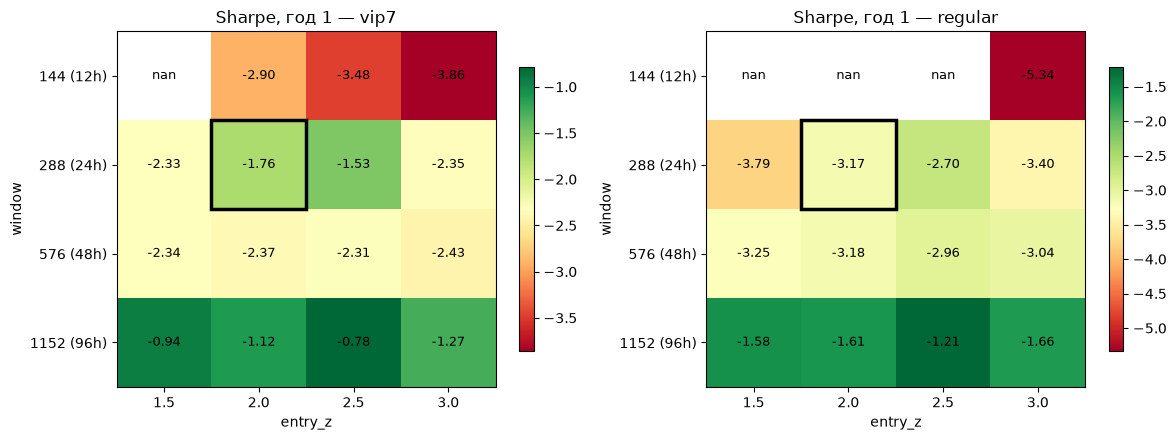

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, tier in zip(axes, ("vip7", "regular")):
    h = heat("sharpe", tier)
    vals = h.drop("window").to_numpy()                       # 4 × 4 числа
    cols = h.drop("window").columns                          # entry_z как строки

    im = ax.imshow(vals, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(WINDOWS)), [f"{w} ({w * 5 / 60:.0f}h)" for w in h["window"]])
    ax.set_xlabel("entry_z")
    ax.set_ylabel("window")
    ax.set_title(f"Sharpe, год 1 — {tier}")

    for i in range(vals.shape[0]):                           # числа в клетках
        for j in range(vals.shape[1]):
            ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=9)

    i0 = list(h["window"]).index(288)                         # рамка вокруг v1
    j0 = cols.index("2.0")
    ax.add_patch(Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, lw=2.5, color="black"))

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "05_grid_sharpe.png", dpi=150)
plt.show()

### Проверка исправления Sharpe

- baseline (288, 2.0) не должен измениться: Sharpe −1.76, return −34.7%;
- клетка (144, 1.5): капитал уходил в минус → `min_equity < 0` и Sharpe = NaN.

In [16]:
check = grid.filter((pl.col("tier") == "vip7") &
                    (((pl.col("window") == 288) & (pl.col("entry_z") == 2.0)) |
                     ((pl.col("window") == 144) & (pl.col("entry_z") == 1.5))))
check.select("name", "window", "entry_z", "total_return", "min_equity", "sharpe")

name,window,entry_z,total_return,min_equity,sharpe
str,i64,f64,f64,f64,f64
"""grid w144 e1.5""",144,1.5,-1.06818,-1762.496726,NaN
"""grid w288 e2.0""",288,2.0,-0.346554,12722.659463,-1.758088


### 4.3b — окна длиннее + исправленный Sharpe

**Исправление:** если капитал хоть раз ≤ 0, Sharpe = NaN (раньше получался мусор, например +0.99 при −107%).
Колонка `min_equity` — самый низкий капитал за период.

**Продлеваем сетку:** окно 1152 (4 дня) было лучше всех → проверяем 2016 (7 дней), 2880 (10 дней), 4032 (14 дней).
- результат продолжает улучшаться или держится → плато, хорошо;
- результат падает → оптимум около 1152.

In [17]:
for w in (2016, 2880, 4032):
    for e in ENTRIES:
        record(f"grid w{w} e{e}", window=w, entry_z=e)

grid = (pl.DataFrame(log)
          .filter(pl.col("name").str.starts_with("grid"))
          .unique(subset=["name", "tier"], keep="first", maintain_order=True))
WINDOWS = (144, 288, 576, 1152, 2016, 2880, 4032)
print("прогонов:", grid.height)      # 7 окон × 4 порога × 2 уровня = 56

for metric in ("sharpe", "total_return", "min_equity", "n_trades"):
    print(f"\n=== {metric} (VIP-7) ===")
    print(heat(metric))

print("\n=== sharpe (Regular) ===")
print(heat("sharpe", "regular"))

прогонов: 56

=== sharpe (VIP-7) ===
shape: (7, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 1.5       ┆ 2.0       ┆ 2.5       ┆ 3.0       │
│ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64    ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 144    ┆ NaN       ┆ -2.903703 ┆ -3.477037 ┆ -3.862873 │
│ 288    ┆ -2.3342   ┆ -1.758088 ┆ -1.526855 ┆ -2.347067 │
│ 576    ┆ -2.335538 ┆ -2.374348 ┆ -2.305776 ┆ -2.426646 │
│ 1152   ┆ -0.938009 ┆ -1.120598 ┆ -0.78437  ┆ -1.266249 │
│ 2016   ┆ -0.789028 ┆ -0.894462 ┆ -0.586816 ┆ -1.260297 │
│ 2880   ┆ -0.670151 ┆ -0.470804 ┆ -1.025203 ┆ -1.590589 │
│ 4032   ┆ -2.114662 ┆ -1.325066 ┆ -0.5023   ┆ 0.648071  │
└────────┴───────────┴───────────┴───────────┴───────────┘

=== total_return (VIP-7) ===
shape: (7, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 1.5       ┆ 2.0       ┆ 2.5       ┆ 3.0       │
│ ---    ┆ ---      

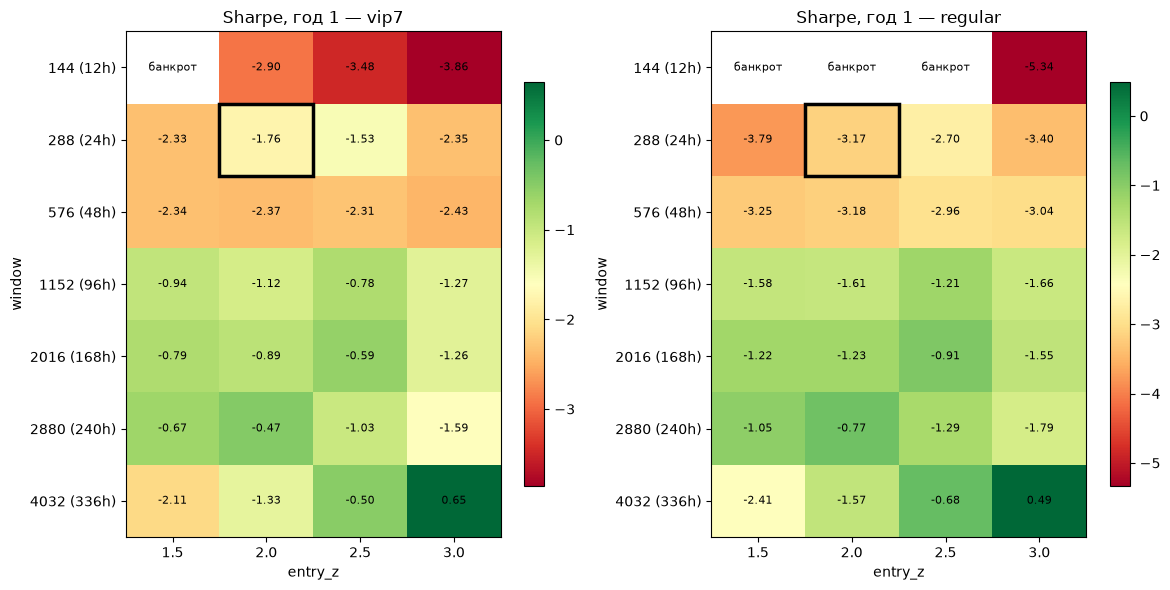

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, tier in zip(axes, ("vip7", "regular")):
    h = heat("sharpe", tier)
    vals = h.drop("window").to_numpy()                       # 7 × 4 числа (NaN = банкротство)
    cols = h.drop("window").columns

    im = ax.imshow(vals, cmap="RdYlGn", aspect="auto")       # NaN → пустая клетка
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(h)), [f"{w} ({w * 5 / 60:.0f}h)" for w in h["window"]])
    ax.set_xlabel("entry_z")
    ax.set_ylabel("window")
    ax.set_title(f"Sharpe, год 1 — {tier}")

    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            txt = "банкрот" if np.isnan(vals[i, j]) else f"{vals[i, j]:.2f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8)

    i0 = list(h["window"]).index(288)                         # рамка вокруг v1
    j0 = cols.index("2.0")
    ax.add_patch(Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, lw=2.5, color="black"))

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "05_grid_sharpe.png", dpi=150)
plt.show()

### Сколько сделок в одной клетке 

In [19]:
with pl.Config(tbl_rows=-1):
    print(heat("n_trades"))
    print(heat("min_equity"))

shape: (7, 5)
┌────────┬──────┬─────┬─────┬─────┐
│ window ┆ 1.5  ┆ 2.0 ┆ 2.5 ┆ 3.0 │
│ ---    ┆ ---  ┆ --- ┆ --- ┆ --- │
│ i64    ┆ i64  ┆ i64 ┆ i64 ┆ i64 │
╞════════╪══════╪═════╪═════╪═════╡
│ 144    ┆ 1088 ┆ 854 ┆ 663 ┆ 453 │
│ 288    ┆ 593  ┆ 483 ┆ 368 ┆ 274 │
│ 576    ┆ 315  ┆ 244 ┆ 187 ┆ 143 │
│ 1152   ┆ 193  ┆ 142 ┆ 111 ┆ 91  │
│ 2016   ┆ 123  ┆ 90  ┆ 74  ┆ 53  │
│ 2880   ┆ 109  ┆ 75  ┆ 53  ┆ 36  │
│ 4032   ┆ 81   ┆ 58  ┆ 39  ┆ 27  │
└────────┴──────┴─────┴─────┴─────┘
shape: (7, 5)
┌────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ window ┆ 1.5          ┆ 2.0          ┆ 2.5          ┆ 3.0          │
│ ---    ┆ ---          ┆ ---          ┆ ---          ┆ ---          │
│ i64    ┆ f64          ┆ f64          ┆ f64          ┆ f64          │
╞════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ 144    ┆ -1762.496726 ┆ 438.779495   ┆ 6210.499653  ┆ 8340.595119  │
│ 288    ┆ 9824.76981   ┆ 12722.659463 ┆ 13993.619369 ┆ 12627.783371 │
│ 576  

### Почему длинное окно лучше — причины выходов

Сравниваем v1 (288, 2.0) с центром плато (2016, 2.5) и пиком (4032, 3.0).

Смотрим:
- стало ли меньше потерь по **time**;
- стал ли чаще срабатывать **stop** (z-стоп начал ловить тренды?);
- сколько сделок в пике (4032, 3.0).

In [20]:
def trades_for(window, entry_z, tier="vip7"):
    """Сделки года 1 для одной комбинации."""
    zz = rolling_zscore(spread, window)
    r = run_backtest_fast(open_a[cut], open_b[cut], close_a[cut], close_b[cut],
                          tradable[cut], zz[cut], tier, fa[cut], fb[cut], entry_z=entry_z)
    return pl.DataFrame(r["trades"]).with_columns(
        (pl.col("exit_t") - pl.col("entry_t")).alias("bars"))      # сколько свечей держали

for w, e in [(288, 2.0), (2016, 2.5), (4032, 3.0)]:
    t = trades_for(w, e)
    print(f"\n=== window {w}, entry {e}: {t.height} сделок, итог {t['pnl'].sum():.0f} ===")
    print(t.group_by("reason")
           .agg(n=pl.len(),
                avg_pnl=pl.col("pnl").mean(),
                total_pnl=pl.col("pnl").sum(),
                avg_hours=(pl.col("bars").mean() * 5 / 60))         # средняя длительность в часах
           .sort("reason"))


=== window 288, entry 2.0: 483 сделок, итог -6931 ===
shape: (4, 5)
┌────────┬─────┬─────────────┬───────────────┬───────────┐
│ reason ┆ n   ┆ avg_pnl     ┆ total_pnl     ┆ avg_hours │
│ ---    ┆ --- ┆ ---         ┆ ---           ┆ ---       │
│ str    ┆ u32 ┆ f64         ┆ f64           ┆ f64       │
╞════════╪═════╪═════════════╪═══════════════╪═══════════╡
│ end    ┆ 1   ┆ -20.635126  ┆ -20.635126    ┆ 8.666667  │
│ mean   ┆ 384 ┆ 32.465847   ┆ 12466.885147  ┆ 11.098741 │
│ stop   ┆ 92  ┆ -155.100536 ┆ -14269.249346 ┆ 3.616848  │
│ time   ┆ 6   ┆ -851.34641  ┆ -5108.078458  ┆ 48.0      │
└────────┴─────┴─────────────┴───────────────┴───────────┘

=== window 2016, entry 2.5: 74 сделок, итог -1627 ===
shape: (3, 5)
┌────────┬─────┬─────────────┬──────────────┬───────────┐
│ reason ┆ n   ┆ avg_pnl     ┆ total_pnl    ┆ avg_hours │
│ ---    ┆ --- ┆ ---         ┆ ---          ┆ ---       │
│ str    ┆ u32 ┆ f64         ┆ f64          ┆ f64       │
╞════════╪═════╪═════════════╪══════════

### Вывод 4.3b

**Исправление Sharpe:** если капитал хоть раз ≤ 0 → Sharpe = NaN («банкрот»), в таблице добавлена колонка `min_equity`.
Банкротов 1 на VIP-7 (144, 1.5: min_equity = −$1,762) и 3 на Regular (окно 144). Baseline не изменился (−1.76).

**Sharpe, VIP-7:**

| window       | 1.5   | 2.0       | 2.5       | 3.0       |
|--------------|-------|-----------|-----------|-----------|
| 144 (12 ч)   | банкрот | −2.90   | −3.48     | −3.86     |
| 288 (v1)     | −2.33 | **−1.76** | −1.53     | −2.35     |
| 576 (2 д)    | −2.34 | −2.37     | −2.31     | −2.43     |
| 1152 (4 д)   | −0.94 | −1.12     | −0.78     | −1.27     |
| 2016 (7 д)   | −0.79 | −0.89     | **−0.59** | −1.26     |
| 2880 (10 д)  | −0.67 | −0.47     | −1.03     | −1.59     |
| 4032 (14 д)  | −2.11 | −1.33     | −0.50     | +0.65     |

**Return, VIP-7:** v1 = −34.7%; область окон 4–10 дней × порог 1.5–2.5 = **−8…−19%**.

**Сделок:** v1 = 483; окно 2016 = 74–123; окно 4032, вход 3.0 = **27**.

**Что видно:**
1. **Плато:** окна 1152–2880 (4–10 дней) × порог 1.5–2.5. Sharpe от −0.47 до −1.12 во всех 12 клетках,
   на Regular то же самое. Убыток в 2–4 раза меньше, чем у v1.
2. **Клетка (4032, 3.0) в плюсе (+4.9%), но это одиночный пик:** соседи хуже (−0.50, −1.59),
   и всего 27 сделок (6 прибыльных по mean). → **не выбираем.**
3. Стратегия всё ещё в минусе, но гораздо ближе к нулю.

## 14. Эксперимент 4.2b — time-стоп для длинного окна

**Что увидели:** у окна 2016 (7 дней) половина сделок (37 из 74) закрывается по time через 48 ч,
а удачные сделки идут к среднему в среднем 26 ч. Time-выходы теряют немного (−$98) → похоже,
сделки просто **не успевают** вернуться к недельному среднему.

**Гипотеза:** time-стоп 48 ч подобран под окно 1 день. Для окна 4–10 дней нужен длиннее.

**Сетка:** окна 1152 / 2016 / 2880 × max_hold 576 / 1152 / 2016 / 4032
(2, 4, 7, 14 дней) × entry 2.0 и 2.5.

**Риск:** чем дольше держим, тем меньше сделок (одна позиция за раз) и тем меньше выборка.
Смотрим не только Sharpe, но и n_trades.

In [21]:
# 4.2b: окно × max_hold для двух порогов
for e in (2.0, 2.5):
    for w in (1152, 2016, 2880):
        for h in (576, 1152, 2016, 4032):
            record(f"hold w{w} e{e} h{h}", window=w, entry_z=e, max_hold=h)

hold = (pl.DataFrame(log)
          .filter(pl.col("name").str.starts_with("hold"))
          .unique(subset=["name", "tier"], keep="first", maintain_order=True))
print("прогонов:", hold.height)     # 2 × 3 × 4 × 2 = 48


def heat_hold(metric, entry, tier="vip7"):
    """Таблица window × max_hold для одного порога входа."""
    return (hold.filter((pl.col("tier") == tier) & (pl.col("entry_z") == entry))
                .pivot(on="max_hold", index="window", values=metric)
                .sort("window"))

with pl.Config(tbl_rows=-1):
    for e in (2.0, 2.5):
        for metric in ("sharpe", "total_return", "n_trades"):
            print(f"\n=== {metric} | entry {e} | VIP-7 ===")
            print(heat_hold(metric, e))
        print(f"\n=== sharpe | entry {e} | Regular ===")
        print(heat_hold("sharpe", e, "regular"))

прогонов: 48

=== sharpe | entry 2.0 | VIP-7 ===
shape: (3, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 576       ┆ 1152      ┆ 2016      ┆ 4032      │
│ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64    ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1152   ┆ -1.120598 ┆ -1.035879 ┆ -0.952485 ┆ -0.952485 │
│ 2016   ┆ -0.894462 ┆ -0.47704  ┆ -0.973668 ┆ -0.601219 │
│ 2880   ┆ -0.470804 ┆ -0.468598 ┆ -0.970925 ┆ -0.924094 │
└────────┴───────────┴───────────┴───────────┴───────────┘

=== total_return | entry 2.0 | VIP-7 ===
shape: (3, 5)
┌────────┬───────────┬───────────┬───────────┬───────────┐
│ window ┆ 576       ┆ 1152      ┆ 2016      ┆ 4032      │
│ ---    ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64    ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1152   ┆ -0.192176 ┆ -0.198477 ┆ -0.188293 ┆ -0.18829

### Вывод 4.2b

- Длиннее time-стоп помогает **только** в строке (2016, 2.5): Sharpe −0.59 → −0.21.
  Соседние строки (окна 1152 и 2880, entry 2.0) этого не подтверждают → плато нет.
- Разница −8.1% → −5.0% = ≈ $620 ≈ 2 сделки (одна удачная ≈ $370) → шум.
- Сделок почти столько же (74 → 67): time-стоп меняет исход лишь нескольких сделок.
- **Решение:** time-стоп оставляем 576 (2 дня).
- **v2 = window 2016, entry 2.5**, остальное как в v1 (центр плато из 4.3).
- Настройку на году 1 заканчиваем: при ~75 сделках в год дальнейший перебор = подгонка под шум.

## 15. Эксперимент 4.5 — β регрессией. Шаг 0: какой β на самом деле?

Сейчас β = 1: считаем, что ETH двигается ровно как BTC.
Считаем настоящий β на году 1 двумя способами:

- **по доходностям:** на сколько % двигается ETH при движении BTC на 1% (5-минутные свечи);
- **по уровням:** наклон линии ln(ETH) от ln(BTC).

И отдельно по кварталам, чтобы увидеть, стабилен ли β.

**Решение:**
- β около 1 (0.9–1.1) и стабилен → регрессия ничего не даст, пропускаем;
- β далеко от 1 или сильно меняется → делаем 4.5.

In [22]:
la, lb = np.log(close_a[cut]), np.log(close_b[cut])      # ln цен, год 1
ra, rb = np.diff(la), np.diff(lb)                         # 5-минутные доходности

beta_ret = np.cov(ra, rb)[0, 1] / np.var(rb, ddof=1)     # β по доходностям
beta_lvl = np.polyfit(lb, la, 1)[0]                       # β по уровням (наклон линии)
corr = np.corrcoef(ra, rb)[0, 1]                          # насколько синхронно ходят
print(f"β по доходностям: {beta_ret:.3f} | β по уровням: {beta_lvl:.3f} | корреляция: {corr:.3f}")

# β по кварталам: стабилен или «гуляет»?
t = pl.from_epoch(df["open_time"][cut], time_unit="ms")
q = (t.dt.year().cast(pl.Utf8) + "-Q" + t.dt.quarter().cast(pl.Utf8)).to_numpy()[1:]   # под доходности

for name in sorted(set(q)):
    m = q == name
    b = np.cov(ra[m], rb[m])[0, 1] / np.var(rb[m], ddof=1)
    print(f"{name}: β = {b:.3f}")

β по доходностям: 1.184 | β по уровням: 0.967 | корреляция: 0.763
2024-Q4: β = 1.013
2025-Q1: β = 1.116
2025-Q2: β = 1.417
2025-Q3: β = 1.465


## 16. Эксперимент 4.5 — β регрессией

β = на сколько % двигается ETH, когда BTC двигается на 1%. В v1 мы считали β = 1.

| Период       | β (по доходностям) |
|--------------|--------------------|
| весь год 1   | **1.18**           |
| 2024-Q4      | 1.01               |
| 2025-Q1      | 1.12               |
| 2025-Q2      | **1.42**           |
| 2025-Q3      | **1.47**           |

Корреляция 5-минутных доходностей ETH и BTC: 0.76.

**Что видно:**
1. **β ≠ 1 и растёт весь год:** 1.0 → 1.47. Во второй половине года ETH реагировал на рынок в ~1.5 раза сильнее BTC.
2. **Худшие сделки v1 — как раз в Q2–Q3** (−1,906 май, −1,219 июль, −851 август), где β ≈ 1.4–1.5.
3. **Почему это плохо для β = 1:** рынок +5% → BTC +5%, ETH +7.3%. При β = 1 это выглядит как
   «ETH обогнал BTC на 2.3%», хотя на деле ETH просто сильнее реагирует. Мы шортим спред, а он
   продолжает «убегать» вместе с рынком → ложный «тренд».
4. **Фиксированный β не подойдёт:** 1.18 на весь год даст перехедж в Q4 и недохедж в Q3.
   → нужен **скользящий β** (считаем по последним N свечам, как среднее и std для z).

β по уровням (0.97) не используем: он меряет сдвиг цен за весь год, и его тянет общий тренд.
Для хеджа важна реакция ETH на движения BTC **сейчас** → β по доходностям.

### План

| Шаг | Что делаем | Файл |
|-----|------------|------|
| 1 | скользящий β + спред, который не прыгает при смене β; тесты | `src/signals.py` |
| 2 | движок: нога BTC = β × $10,000 (иначе хедж не сходится); тесты | `src/engine_numba.py` |
| 3 | `evaluate` с β; эксперимент на v1 (288, 2.0) и v2 (2016, 2.5) | `src/research.py`, ноутбук |

**Что хотим увидеть:** меньше ложных «трендов» → меньше потерь по stop и time, особенно в Q2–Q3.

### 4.5 — эксперимент: скользящий β

Сравниваем β = 1 (как сейчас) со скользящим β для двух версий стратегии:
- **v1** = window 288, entry 2.0;
- **v2** = window 2016, entry 2.5.

**Окно β:** 2016 (7 дней), 4032 (14 дней), 8640 (30 дней).
Короткое окно быстро подстраивается, но β «шумный»; длинное — стабильнее, но запаздывает.

**Нюанс:** первые N свечей β ещё не посчитан → в начале года сделок нет (для окна 30 дней это первый месяц).

**Что хотим увидеть:** лучше, чем β = 1, при **нескольких** окнах β и для **обеих** версий.

In [23]:
# 4.5: β = 1 против скользящего β, для v1 и v2
VERSIONS = {"v1": dict(window=288, entry_z=2.0),
            "v2": dict(window=2016, entry_z=2.5)}

for vname, params in VERSIONS.items():
    record(f"beta {vname} bw0", **params)                              # β = 1 (для сравнения)
    for bw in (2016, 4032, 8640):
        record(f"beta {vname} bw{bw}", beta_window=bw, **params)

beta_tab = (pl.DataFrame(log)
              .filter(pl.col("name").str.starts_with("beta"))
              .unique(subset=["name", "tier"], keep="first", maintain_order=True))

with pl.Config(tbl_rows=-1):
    for tier in ("vip7", "regular"):
        print(f"\n=== {tier} ===")
        print(beta_tab.filter(pl.col("tier") == tier)
                      .select("name", "window", "entry_z", "beta_window", "n_trades",
                              "win_rate", "profit_factor", "total_return", "max_drawdown", "sharpe"))

/Users/system/Downloads/Quant_Project/src/signals.py:16: RuntimeWarning: invalid value encountered in divide
  return (spread - mean) / std



=== vip7 ===
shape: (8, 10)
┌────────────┬────────┬─────────┬────────────┬───┬────────────┬────────────┬───────────┬───────────┐
│ name       ┆ window ┆ entry_z ┆ beta_windo ┆ … ┆ profit_fac ┆ total_retu ┆ max_drawd ┆ sharpe    │
│ ---        ┆ ---    ┆ ---     ┆ w          ┆   ┆ tor        ┆ rn         ┆ own       ┆ ---       │
│ str        ┆ i64    ┆ f64     ┆ ---        ┆   ┆ ---        ┆ ---        ┆ ---       ┆ f64       │
│            ┆        ┆         ┆ i64        ┆   ┆ f64        ┆ f64        ┆ f64       ┆           │
╞════════════╪════════╪═════════╪════════════╪═══╪════════════╪════════════╪═══════════╪═══════════╡
│ beta v1    ┆ 288    ┆ 2.0     ┆ 0          ┆ … ┆ 0.767516   ┆ -0.346554  ┆ -0.372496 ┆ -1.758088 │
│ bw0        ┆        ┆         ┆            ┆   ┆            ┆            ┆           ┆           │
│ beta v1    ┆ 288    ┆ 2.0     ┆ 2016       ┆ … ┆ 0.582746   ┆ -0.602761  ┆ -0.611268 ┆ -3.580502 │
│ bw2016     ┆        ┆         ┆            ┆   ┆            

In [25]:
from src.signals import rolling_beta, hedged_spread

# 1) какие β на реальных данных (год 1)? Ожидаем ~1.0–1.5, как в диагностике по кварталам
for bw in (2016, 4032, 8640):
    b = rolling_beta(close_a, close_b, bw)[cut]
    print(f"окно β {bw}: min {np.nanmin(b):.2f} | среднее {np.nanmean(b):.2f} | max {np.nanmax(b):.2f}")

# 2) сколько сделок и как они закрывались: v2 с β = 1 и с β (окно 30 дней)
def trades_beta(window, entry_z, bw):
    if bw > 0:
        bb = rolling_beta(close_a, close_b, bw)
        sp = hedged_spread(close_a, close_b, bb)
    else:
        bb = None
        sp = log_spread(close_a, close_b)
    zz = rolling_zscore(sp, window)
    r = run_backtest_fast(open_a[cut], open_b[cut], close_a[cut], close_b[cut], tradable[cut],
                          zz[cut], "vip7", fa[cut], fb[cut], entry_z=entry_z,
                          beta=None if bb is None else bb[cut])
    return pl.DataFrame(r["trades"])

for bw in (0, 8640):
    t = trades_beta(2016, 2.5, bw)
    print(f"\n=== v2, окно β {bw}: {t.height} сделок, итог {t['pnl'].sum():.0f} ===")
    print(t.group_by("reason")
           .agg(n=pl.len(), avg_pnl=pl.col("pnl").mean(), total_pnl=pl.col("pnl").sum())
           .sort("reason"))

окно β 2016: min 0.68 | среднее 1.27 | max 1.94
окно β 4032: min 0.78 | среднее 1.27 | max 1.73
окно β 8640: min 0.89 | среднее 1.27 | max 1.65

=== v2, окно β 0: 74 сделок, итог -1627 ===
shape: (3, 4)
┌────────┬─────┬─────────────┬──────────────┐
│ reason ┆ n   ┆ avg_pnl     ┆ total_pnl    │
│ ---    ┆ --- ┆ ---         ┆ ---          │
│ str    ┆ u32 ┆ f64         ┆ f64          │
╞════════╪═════╪═════════════╪══════════════╡
│ mean   ┆ 18  ┆ 371.034905  ┆ 6678.628284  │
│ stop   ┆ 19  ┆ -245.374879 ┆ -4662.122692 │
│ time   ┆ 37  ┆ -98.480112  ┆ -3643.764149 │
└────────┴─────┴─────────────┴──────────────┘

=== v2, окно β 8640: 72 сделок, итог -2424 ===
shape: (3, 4)
┌────────┬─────┬─────────────┬──────────────┐
│ reason ┆ n   ┆ avg_pnl     ┆ total_pnl    │
│ ---    ┆ --- ┆ ---         ┆ ---          │
│ str    ┆ u32 ┆ f64         ┆ f64          │
╞════════╪═════╪═════════════╪══════════════╡
│ mean   ┆ 22  ┆ 328.730625  ┆ 7232.073756  │
│ stop   ┆ 21  ┆ -226.615174 ┆ -4758.918664 │

### Вывод 4.5 — скользящий β

| Версия           | β = 1      | β (7 д) | β (14 д) | β (30 д) |
|------------------|------------|---------|----------|----------|
| v1 (288, 2.0)    | **−1.76**  | −3.58   | −3.27    | −3.82    |
| v2 (2016, 2.5)   | **−0.59**  | −1.01   | −1.15    | −0.90    |

(Sharpe, VIP-7, год 1)

- **Хуже во всех 6 вариантах.** У v1 — намного (return −35% → −56…−62%), у v2 — немного (−8% → −12…−15%).
- **Ошибки не видно:** у v2 с β структура сделок почти та же (72 против 74 сделок).
  Больше сделок доходят до среднего (22 против 18), но time-выходы дороже (−$169 против −$98).
- Для v2 разница −$800 ≈ 2 удачные сделки → на уровне шума.
- **Почему не помогло (гипотеза):** при β = 1 в спреде остаётся часть «движения рынка», которая на коротких
  отрезках тоже возвращается к среднему, и стратегия на ней зарабатывала. Правильный хедж её убрал.
- **Решение:** β = 1 оставляем. Код скользящего β остаётся (по умолчанию выключен, покрыт тестами).

## 15. Проверка v2 по кварталам (год 1)

**v1** = window 288, entry 2.0. **v2** = window 2016, entry 2.5. Остальное одинаково (β = 1).

Делим год 1 на 4 квартала и считаем PnL каждого. Если v2 лучше v1 в 3–4 кварталах из 4,
улучшение устойчивое. Если только в одном, оно держится на удачном периоде.

In [26]:
def quarterly(window, entry_z, tier="vip7"):
    """PnL и число входов по кварталам года 1."""
    zz = rolling_zscore(spread, window)
    r = run_backtest_fast(open_a[cut], open_b[cut], close_a[cut], close_b[cut],
                          tradable[cut], zz[cut], tier, fa[cut], fb[cut], entry_z=entry_z)

    eq = r["equity"]
    pnl_bar = np.diff(np.concatenate([[config.CAPITAL], eq]))      # изменение капитала на каждой свече

    t = pl.from_epoch(df["open_time"][cut], time_unit="ms")         # время каждой свечи
    q = t.dt.year().cast(pl.Utf8) + "-Q" + t.dt.quarter().cast(pl.Utf8)   # "2024-Q4", "2025-Q1", …

    entries = np.zeros(len(eq), dtype=int)
    entries[[tr["entry_t"] for tr in r["trades"]]] = 1              # 1 на свече входа

    return (pl.DataFrame({"quarter": q, "pnl": pnl_bar, "entries": entries})
              .group_by("quarter")
              .agg(pl.col("pnl").sum().round(0), pl.col("entries").sum())
              .sort("quarter"))

v1 = quarterly(288, 2.0).rename({"pnl": "v1_pnl", "entries": "v1_trades"})
v2 = quarterly(2016, 2.5).rename({"pnl": "v2_pnl", "entries": "v2_trades"})
qt = v1.join(v2, on="quarter").with_columns(
        (pl.col("v2_pnl") > pl.col("v1_pnl")).alias("v2_better"))
qt

quarter,v1_pnl,v1_trades,v2_pnl,v2_trades,v2_better
str,f64,i64,f64,i64,bool
"""2024-Q4""",-3189.0,119,476.0,19,true
"""2025-Q1""",1691.0,124,-160.0,20,false
"""2025-Q2""",-1131.0,129,159.0,16,true
"""2025-Q3""",-4302.0,111,-2102.0,19,true


### Вывод: v2 по кварталам

| Квартал | v1      | v2      | v2 лучше? |
|---------|---------|---------|-----------|
| 2024-Q4 | −3,189  | +476    | ✅        |
| 2025-Q1 | +1,691  | −160    | ❌        |
| 2025-Q2 | −1,131  | +159    | ✅        |
| 2025-Q3 | −4,302  | −2,102  | ✅        |
| Год     | −6,931  | −1,627  |           |

- v2 лучше в **3 из 4** кварталов → улучшение устойчивое, не один удачный период.
- v2 почти в нуле в Q4, Q1 и Q2. Почти весь убыток — Q3 (тренд, β ≈ 1.47).
- v1 нестабилен: один хороший квартал и три плохих.

**Итог исследования на году 1:** v2 = window 2016 (7 дней), entry 2.5, остальное как в v1 (β = 1, стоп 4, time 576).
Параметры фиксируем. Дальше — один тест на году 2.

In [24]:
out = ROOT / "reports" / "research_log_year1.csv"
final_log = pl.DataFrame(log).unique(subset=["name", "tier"], keep="first", maintain_order=True)
final_log.write_csv(out)
print("сохранено:", out, "| запусков в журнале:", final_log.height)

сохранено: /Users/system/Downloads/Quant_Project/reports/research_log_year1.csv | запусков в журнале: 152
